# Phase 2: Probabilistic spread and the 8-neighbour option

In Phase 1 fire *always* jumped to a neighbouring tree. Real fuel is not that obliging: damp leaves or green wood often fail to catch. So now a burning tree ignites each neighbouring tree only with **probability q**:

* **q = 1:** bone-dry fuel. This is exactly Phase 1.
* **lower q:** wetter fuel. A tree can survive one burning neighbour and still catch from another later.

We also add the **Moore** neighbourhood: fire can jump to the 4 diagonal trees as well as the 4 side trees, so it needs fewer trees to get across.

The question: **how does wetter fuel move the critical density?**

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the code is cloned from GitHub if that repo exists; otherwise copy the project folder
# to Google Drive as MyDrive/forest_fire.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/forest_fire"):
    repo = "https://github.com/nhamhhung/forest-fire-spread.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/forest_fire"]).returncode == 0:
        os.chdir("/content/forest_fire")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/forest_fire")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from forest_fire import experiments as ex
from forest_fire.grid import make_forest, ignite_left_edge
from forest_fire.spread import run_fire
from forest_fire.plotting import plot_arrival, plot_phase_diagram, NB_LABEL

## 1. One forest, four spread rules
The same 70%-density forest each time. Colour shows when each tree caught fire; white survived.

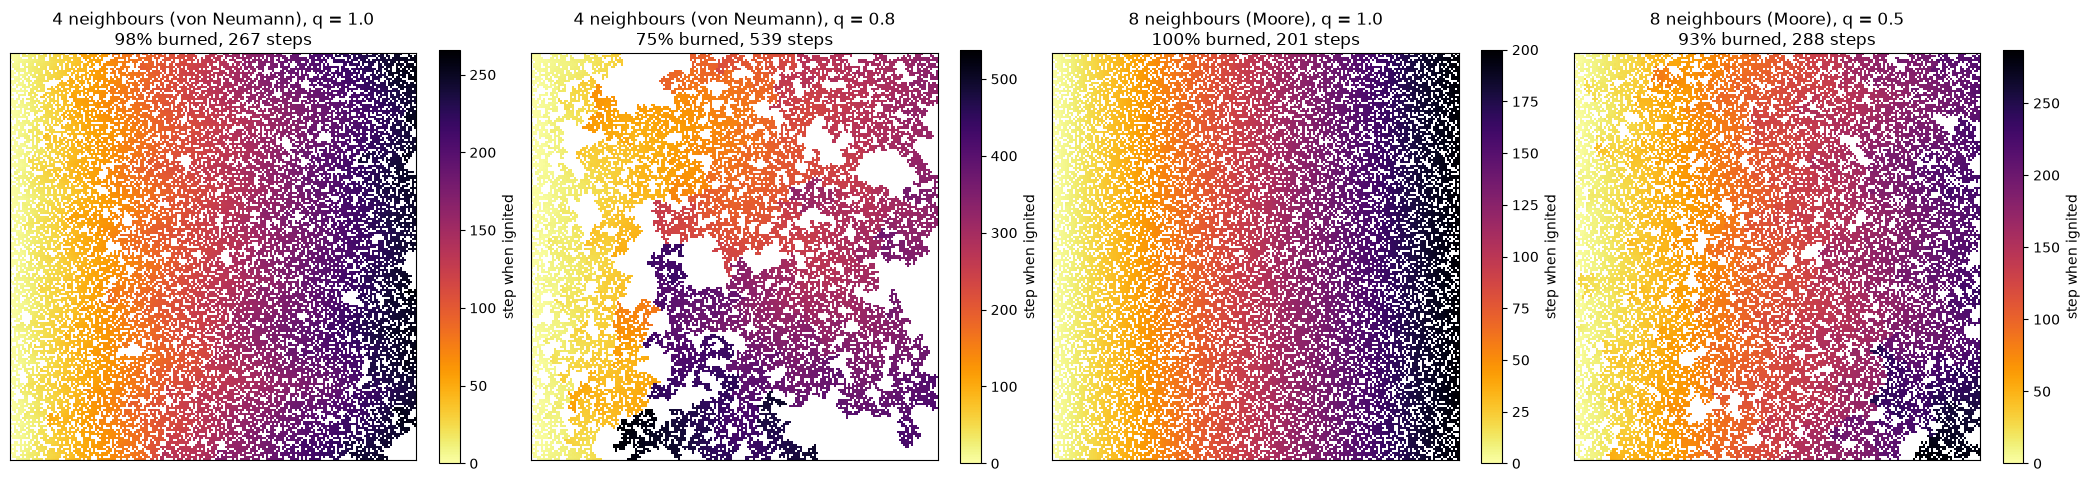

In [2]:
forest = make_forest(200, 0.7, np.random.default_rng(11))
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
for ax, (nb, q) in zip(axes, [("von_neumann", 1.0), ("von_neumann", 0.8), ("moore", 1.0), ("moore", 0.5)]):
    _, arrival, duration = run_fire(ignite_left_edge(forest), q, nb, seed=3)
    m = ex.fire_metrics(forest, q, nb, seed=3)
    plot_arrival(arrival, ax=ax, title=f"{NB_LABEL[nb]}, q = {q}\n{100*m['fraction_burned']:.0f}% burned, {duration} steps")
plt.tight_layout(); plt.show()

* With 4 neighbours, dropping q from 1 to 0.8 leaves large unburnt patches, and the fire takes twice as long. It only just crosses, because 70% density is right at its new threshold (≈ 0.70).
* With 8 neighbours this forest is far above threshold. Even at q = 0.5 the fire burns almost everything.

## 2. A completely full forest: only q matters
With a tree on every cell the question becomes *bond percolation*. Each link between neighbours passes fire with probability q. The exact answer for 4 neighbours is q_c = 1/2; for 8 neighbours it is ≈ 0.250.

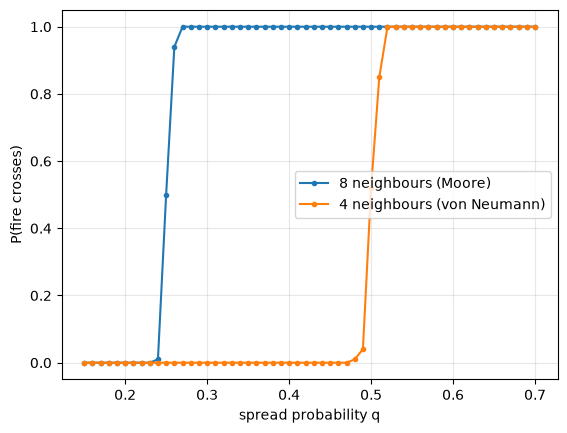

,neighbourhood,q50,known
0,moore,0.2501,0.2504
1,von_neumann,0.5003,0.5000


In [3]:
qs = [round(x, 3) for x in np.arange(0.15, 0.701, 0.01)]
full = pd.concat([ex.spread_probability_sweep(200, qs, 100, 2027, nb) for nb in ("von_neumann", "moore")], ignore_index=True)
bond = pd.DataFrame([{"neighbourhood": nb, "q50": ex.fit_transition(d, x="q")["p50"], "known": ex.BOND_THRESHOLD[nb]}
                     for nb, d in full.groupby("neighbourhood")])
for nb, d in full.groupby("neighbourhood"):
    plt.plot(d["q"], d["spanning_prob"], "o-", ms=3, label=NB_LABEL[nb])
plt.xlabel("spread probability q"); plt.ylabel("P(fire crosses)"); plt.legend(); plt.grid(alpha=.3); plt.show()
bond.round(4)

## 3. Critical density for each q
For each q: a coarse sweep finds the switch, then a fine sweep around it is fitted with a logistic step (as in Phase 1). Fewer q values here than in `scripts/run_phase2.py`, to keep the notebook quick.

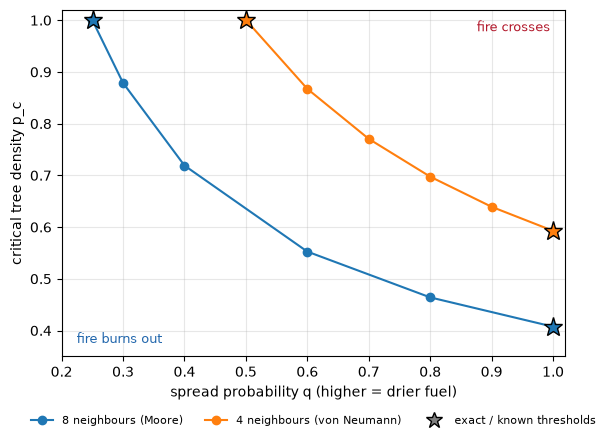

,neighbourhood,q,p50,width
0,von_neumann,1.0,0.5927,0.0059
1,von_neumann,0.9,0.6392,0.0067
2,von_neumann,0.8,0.6975,0.0058
3,von_neumann,0.7,0.7706,0.0062
4,von_neumann,0.6,0.8673,0.0070
5,moore,1.0,0.4074,0.0058
6,moore,0.8,0.4640,0.0062
7,moore,0.6,0.5526,0.0065
8,moore,0.4,0.7190,0.0074
9,moore,0.3,0.8788,0.0076


In [4]:
s = ex.Phase2Settings()
fits = pd.DataFrame([ex.critical_density(200, q, nb, s)[0]
                     for nb, qs_ in [("von_neumann", [1.0, 0.9, 0.8, 0.7, 0.6]), ("moore", [1.0, 0.8, 0.6, 0.4, 0.3])]
                     for q in qs_])
plot_phase_diagram(fits, bond); plt.show()
fits[["neighbourhood", "q", "p50", "width"]].round(4)

## Takeaways
* **Wetter fuel needs a denser forest to carry fire.** With 4 neighbours the critical density rises from 0.593 (q = 1) to about 0.70 (q = 0.8) and 0.87 (q = 0.6). Below q = 1/2 no forest, however dense, carries a fire across.
* **Read the same chart the other way for drought.** Drying the fuel (raising q) *lowers* the density at which a forest becomes fire-prone. A forest that was safely below its threshold in a wet year can be well above it in a drought year, without a single tree being added. Phase 3 models this directly with a dryness parameter, the El Niño lever.
* **Diagonal spread** (8 neighbours) lowers every threshold a lot: 0.407 instead of 0.593 for dry fuel. That is a reminder that thresholds depend on how far fire can jump, e.g. through embers or crown fire.
* The model reproduces three exact or known results: site thresholds 0.5927 / 0.4073 and bond thresholds 1/2 / 0.250.